# 00 — Data Cleaning and Exploratory Analysis

This notebook is the single entry point for data preparation. It cleans the raw scraped data, verifies quality, explores patterns, and saves parquet files that all four feature notebooks read via `load_clean()`.

**Pipeline:** `products.jsonl` → `cleaning.py` → parquet files → EDA visualisations

Cleaning logic lives entirely in `analysis/cleaning.py`. This notebook calls it — it does not duplicate it.

In [1]:
!pip install -q langdetect pyarrow matplotlib seaborn

In [2]:
import sys
from pathlib import Path
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

PROJECT = Path('/content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence')
assert PROJECT.exists(), f'Project folder not found: {PROJECT}'
sys.path.insert(0, str(PROJECT))

sns.set_theme(style='whitegrid')

CLEAN_DIR = PROJECT / 'data' / 'clean'
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR = PROJECT / 'data' / 'checkpoints' / 'ReviewSentiment'

print('Project:', PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence


## 1. Ensure cleaning.py consistency

`cleaning.py` and `sentiment_checkpointed.py` must compute `review_id` the same way. This cell checks and patches if needed. Safe to rerun — it only patches once.

In [3]:
cleaning_path = PROJECT / 'analysis' / 'cleaning.py'
source = cleaning_path.read_text(encoding='utf-8')

OLD_LINE = '    identity = "|".join(str(row.get(c) or "") for c in ("asin", "reviewer_name", "date", "title_clean", "body_clean"))'
NEW_LINE = '    identity = "|".join(str(row.get(c) or "") for c in ("asin", "reviewer_name", "date", "body_clean"))'

if OLD_LINE in source:
    source = source.replace(OLD_LINE, NEW_LINE)
    cleaning_path.write_text(source, encoding='utf-8')
    print('Patched cleaning.py — review_id formula now matches sentiment_checkpointed.py')
elif NEW_LINE in source:
    print('Already consistent — no patch needed')
else:
    print('WARNING: Could not find expected line. Check _review_id in cleaning.py manually.')

# Reload the module to pick up the patch
import analysis.cleaning
importlib.reload(analysis.cleaning)
from analysis.cleaning import load_and_clean, load_raw

## 2. Run the cleaning pipeline

`load_and_clean(save=True)` reads `products.jsonl`, cleans both tables, detects languages, keeps all languages, and saves parquet files.

In [4]:
products_raw, reviews_raw = load_raw()
print(f'Raw products: {len(products_raw)}')
print(f'Raw reviews:  {len(reviews_raw)}')

products, reviews = load_and_clean(save=True, detect_lang=True)

print(f'\nCleaned products: {len(products)}')
print(f'Cleaned reviews:  {len(reviews)}')
print(f'Products dropped: {len(products_raw) - len(products)}')
print(f'Reviews dropped:  {len(reviews_raw) - len(reviews)}')

Raw products: 859
Raw reviews:  9886
Loading raw data...
  859 products, 9886 reviews

Cleaning products...
Products cleaned: 859 rows, 0 duplicates dropped

Cleaning reviews...
  Language distribution:
    - en: 7923 reviews
    - es: 618 reviews
    - fr: 187 reviews
    - pt: 135 reviews
    - de: 105 reviews
    - it: 90 reviews
    - ar: 61 reviews
    - tr: 29 reviews
    - nl: 21 reviews
    - sv: 19 reviews
    - pl: 15 reviews
    - no: 9 reviews
    - ca: 6 reviews
    - da: 6 reviews
    - tl: 5 reviews
    - so: 4 reviews
    - af: 3 reviews
    - ro: 3 reviews
    - et: 3 reviews
    - cy: 2 reviews
    - sk: 2 reviews
    - hu: 2 reviews
    - ja: 1 reviews
    - lv: 1 reviews
    - sl: 1 reviews
Reviews cleaned: 9251 rows
  duplicates dropped   : 0
  <=3 word dropped     : 635
  non-English dropped  : 0

Saved to:
  /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/clean/products_clean.parquet
  /content/drive/MyDrive/Amazon Mini Pr

## 3. Reconnect existing Gemini checkpoints

If Feature B has checkpoint files from a previous run, this cell remaps their review_ids to match the freshly generated parquet. Uses `body_hash` as the bridge — it is identical regardless of review_id formula. Safe to rerun; already-matching checkpoints are skipped.

In [5]:
from analysis.sentiment_checkpointed import prepare_reviews

df_check = prepare_reviews(reviews)
current_ids = set(df_check['review_id'].astype(str))

checkpoint_files = sorted(CHECKPOINT_DIR.glob('*.parquet')) if CHECKPOINT_DIR.exists() else []

if not checkpoint_files:
    print('No Feature B checkpoints found — nothing to remap.')
else:
    for cp in checkpoint_files:
        if '.backup.' in cp.name:
            continue

        saved = pd.read_parquet(cp)
        checkpoint_ids = set(saved['review_id'].astype(str))
        overlap = checkpoint_ids & current_ids
        valid_labels = saved[saved.get('sentiment', pd.Series()).isin(['positive','neutral','negative'])]

        print(f'--- {cp.name} ---')
        print(f'  Valid labels: {len(valid_labels)}')
        print(f'  Match current data: {len(overlap)} / {len(checkpoint_ids)}')

        if len(overlap) == len(checkpoint_ids):
            print(f'  Already matches — skipping')
            continue

        if 'body_hash' not in saved.columns or 'body_hash' not in df_check.columns:
            print(f'  No body_hash column — cannot remap')
            continue

        # Remap using body_hash
        hash_to_new_id = df_check.drop_duplicates('body_hash').set_index('body_hash')['review_id'].to_dict()

        backup = cp.with_suffix('.backup.parquet')
        if not backup.exists():
            saved.to_parquet(backup, index=False)
            print(f'  Backup: {backup.name}')

        saved['review_id'] = saved['body_hash'].map(hash_to_new_id)
        unmapped = saved['review_id'].isna().sum()
        saved = saved.dropna(subset=['review_id'])
        saved.to_parquet(cp, index=False)

        new_overlap = set(saved['review_id'].astype(str)) & current_ids
        print(f'  Remapped: {len(new_overlap)} labels recovered, {unmapped} unmapped')
        print(f'  {"Done" if len(new_overlap) > 0 else "WARNING: zero matches after remap"}')
        print()

--- labels__gemini-3.5-flash-lite__sentiment_v2.parquet ---
  Valid labels: 6470
  Match current data: 9250 / 9250
  Already matches — skipping


## 4. Product cleaning verification

In [6]:
print('=== Product Cleaning Report ===\n')

print('1. ASIN validity')
print(f'   Valid ASINs: {len(products)}')

print('\n2. Missing values')
check_cols = [c for c in ['asin','title','brand','description','price','rating','review_count','image_url'] if c in products.columns]
missing = products[check_cols].isna().sum()
missing_pct = (missing / len(products) * 100).round(1)
display(pd.DataFrame({'missing': missing, 'percent': missing_pct}).sort_values('percent', ascending=False))

print('\n3. Price status')
if 'has_price' in products.columns:
    print(f'   Has price:     {products["has_price"].sum()}')
    print(f'   Missing price: {(~products["has_price"]).sum()}')
if 'price_status' in products.columns:
    display(products['price_status'].value_counts().to_frame('count'))

print('\n4. Key derived columns')
for col in ['combined_text', 'combined_text_no_price', 'bullets_text', 'log_review_count', 'title_word_count']:
    present = col in products.columns
    na = products[col].isna().sum() if present else 'N/A'
    print(f'   {col}: {"present" if present else "MISSING"} (NaN: {na})')

=== Product Cleaning Report ===

1. ASIN validity
   Valid ASINs: 859

2. Missing values


,missing,percent
price,73,8.5
brand,29,3.4
review_count,3,0.3
description,2,0.2
asin,0,0.0
title,0,0.0
rating,0,0.0
image_url,0,0.0



3. Price status
   Has price:     786
   Missing price: 73


,count
price_status,
available,786
variant_or_unpriced,56
unknown,17



4. Key derived columns
   combined_text: present (NaN: 0)
   combined_text_no_price: MISSING (NaN: N/A)
   bullets_text: present (NaN: 0)
   log_review_count: present (NaN: 3)
   title_word_count: present (NaN: 0)


## 5. Review cleaning verification

In [7]:
print('=== Review Cleaning Report ===\n')

print('1. Deduplication')
print(f'   Unique review_ids: {reviews["review_id"].nunique()}')
print(f'   Duplicate IDs:     {reviews["review_id"].duplicated().sum()}')

print('\n2. Missing values')
rev_cols = [c for c in ['body_clean','title_clean','rating','star_sentiment','language','review_id'] if c in reviews.columns]
review_missing = reviews[rev_cols].isna().sum()
review_pct = (review_missing / len(reviews) * 100).round(1)
display(pd.DataFrame({'missing': review_missing, 'percent': review_pct}).sort_values('percent', ascending=False))

print('\n3. Language detection')
print(f'   Languages found: {reviews["language"].nunique()}')
print(f'   All languages KEPT (no filtering)')
display(reviews['language'].value_counts().head(15).to_frame('count'))

print('\n4. Star sentiment distribution')
display(reviews['star_sentiment'].value_counts().to_frame('count'))

print('\n5. Text quality')
reviews['word_count_eda'] = reviews['body_clean'].fillna('').str.split().str.len()
print(f'   Min words:    {reviews["word_count_eda"].min()}')
print(f'   Median words: {reviews["word_count_eda"].median():.0f}')
print(f'   Max words:    {reviews["word_count_eda"].max()}')

=== Review Cleaning Report ===

1. Deduplication
   Unique review_ids: 9251
   Duplicate IDs:     0

2. Missing values


,missing,percent
body_clean,0,0.0
title_clean,0,0.0
rating,0,0.0
star_sentiment,0,0.0
language,0,0.0
review_id,0,0.0



3. Language detection
   Languages found: 25
   All languages KEPT (no filtering)


,count
language,
en,7923
es,618
fr,187
pt,135
de,105
it,90
ar,61
tr,29
nl,21



4. Star sentiment distribution


,count
star_sentiment,
positive,8484
negative,433
neutral,334



5. Text quality
   Min words:    4
   Median words: 38
   Max words:    992


In [8]:
# Safety check: ensure review_id exists
if 'review_id' not in reviews.columns:
    print('review_id missing from clean reviews — generating via prepare_reviews()')
    from analysis.sentiment_checkpointed import prepare_reviews
    reviews = prepare_reviews(reviews)
    # Re-save so all features see it
    reviews.to_parquet(CLEAN_DIR / 'reviews_clean.parquet', index=False)
    print(f'Regenerated with {reviews["review_id"].nunique()} unique IDs')
else:
    print(f'review_id present: {reviews["review_id"].nunique()} unique IDs')

review_id present: 9251 unique IDs


## 6. Product EDA

/tmp/ipykernel_13256/2101928257.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0,0], palette='viridis')


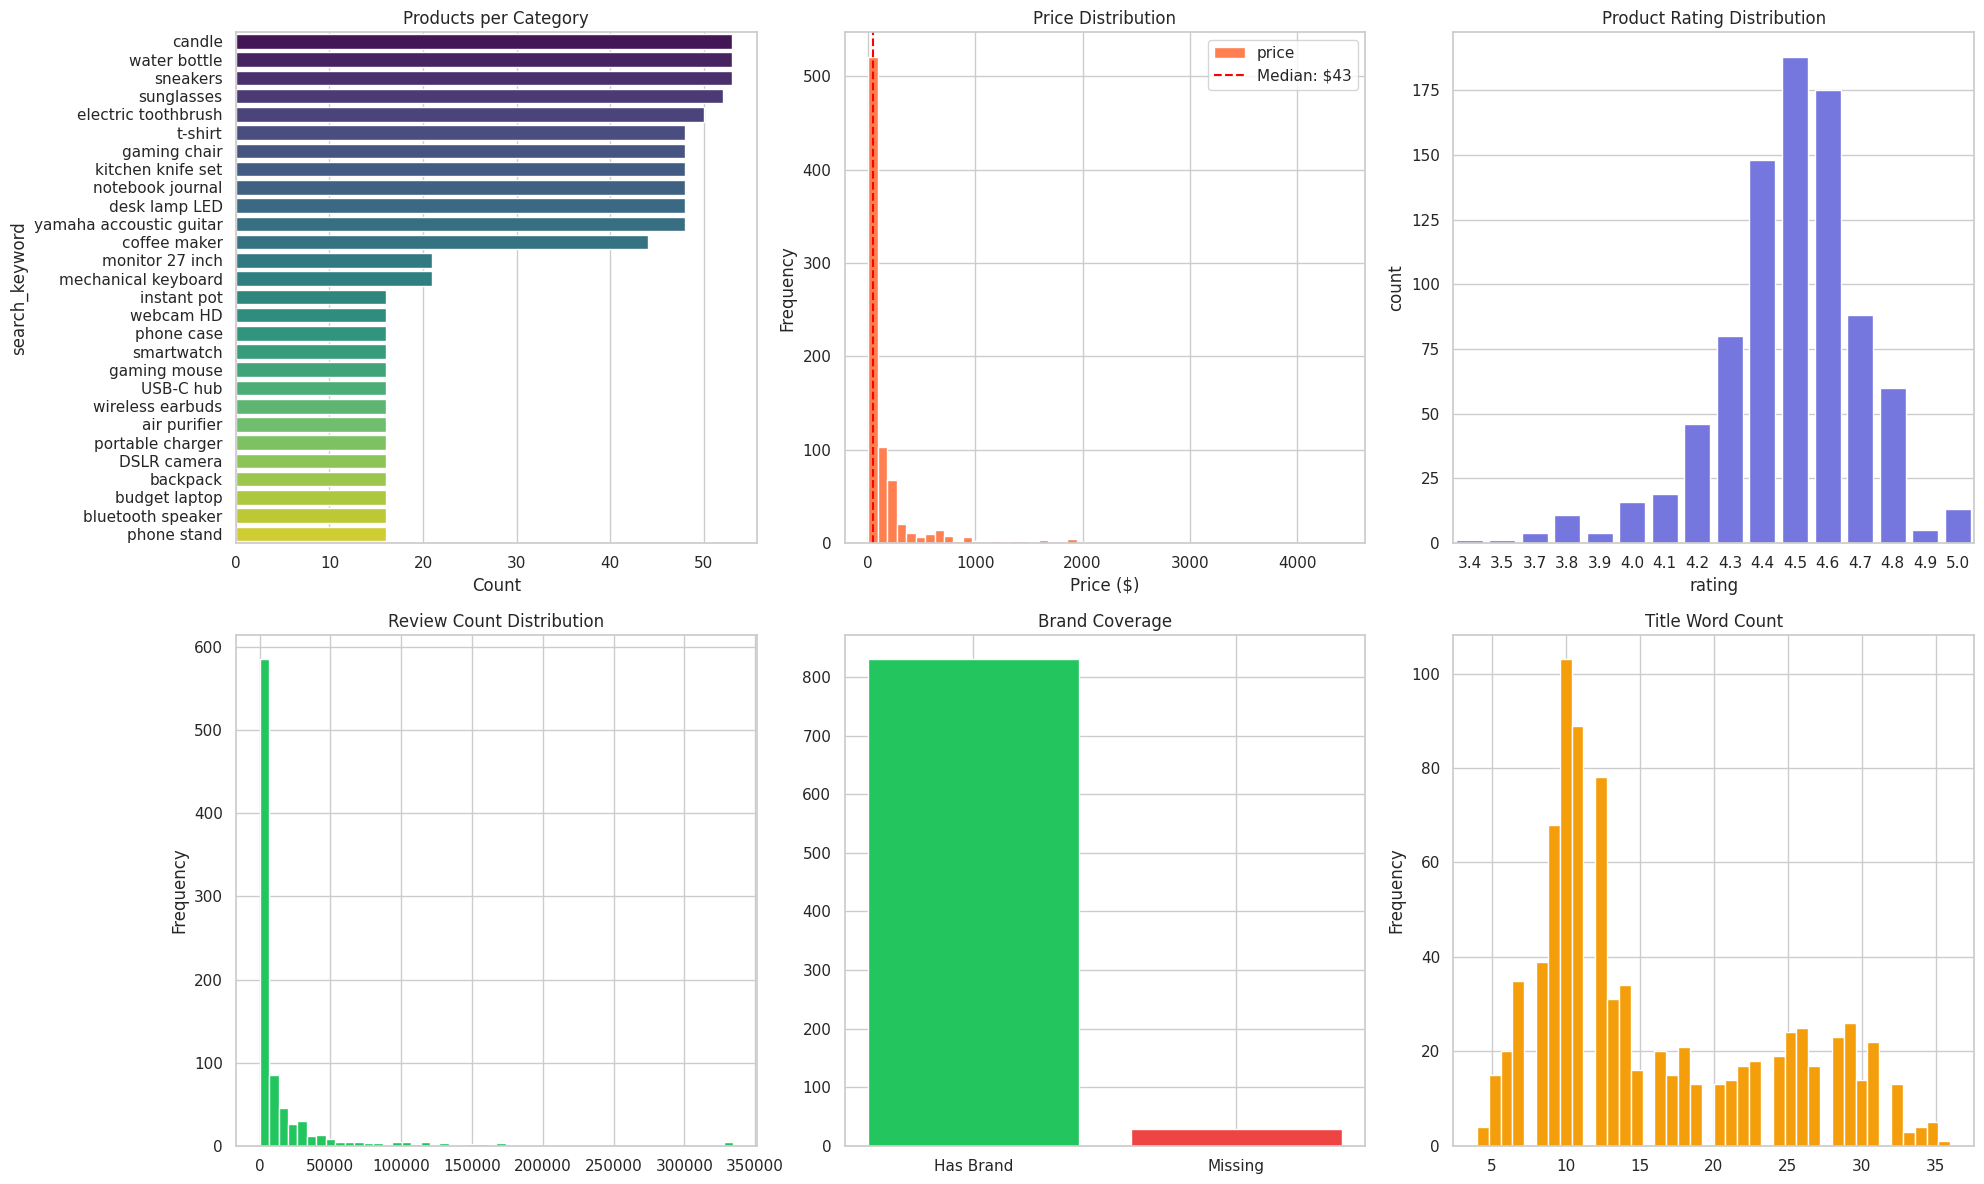

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

cat_counts = products['search_keyword'].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Products per Category')
axes[0,0].set_xlabel('Count')

if 'price' in products.columns:
    products['price'].dropna().plot.hist(bins=50, ax=axes[0,1], color='coral', edgecolor='white')
    axes[0,1].set_title('Price Distribution')
    axes[0,1].set_xlabel('Price ($)')
    axes[0,1].axvline(products['price'].median(), color='red', linestyle='--',
                       label=f"Median: ${products['price'].median():.0f}")
    axes[0,1].legend()

if 'rating' in products.columns:
    sns.countplot(data=products, x='rating', ax=axes[0,2], color='#6366F1')
    axes[0,2].set_title('Product Rating Distribution')

if 'review_count' in products.columns:
    products['review_count'].dropna().plot.hist(bins=50, ax=axes[1,0], color='#22C55E', edgecolor='white')
    axes[1,0].set_title('Review Count Distribution')

brand_na = products['brand'].isna().sum()
axes[1,1].bar(['Has Brand', 'Missing'], [len(products)-brand_na, brand_na], color=['#22C55E','#EF4444'])
axes[1,1].set_title('Brand Coverage')

if 'title_word_count' in products.columns:
    products['title_word_count'].plot.hist(bins=40, ax=axes[1,2], color='#F59E0B', edgecolor='white')
    axes[1,2].set_title('Title Word Count')

plt.tight_layout()
plt.savefig(CLEAN_DIR / 'product_eda.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Review EDA

/tmp/ipykernel_13256/3143777857.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lang_counts.values, y=lang_counts.index, ax=axes[0,0], palette='viridis')
/tmp/ipykernel_13256/3143777857.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=reviews, x='star_sentiment', order=['positive','neutral','negative'],
/tmp/ipykernel_13256/3143777857.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rev_per_cat.values, y=rev_per_cat.index, ax=axes[1,1], palette='Set2')
/tmp/ipykernel_13256/3143777857.py:23: FutureWarning: 

Passing `pa

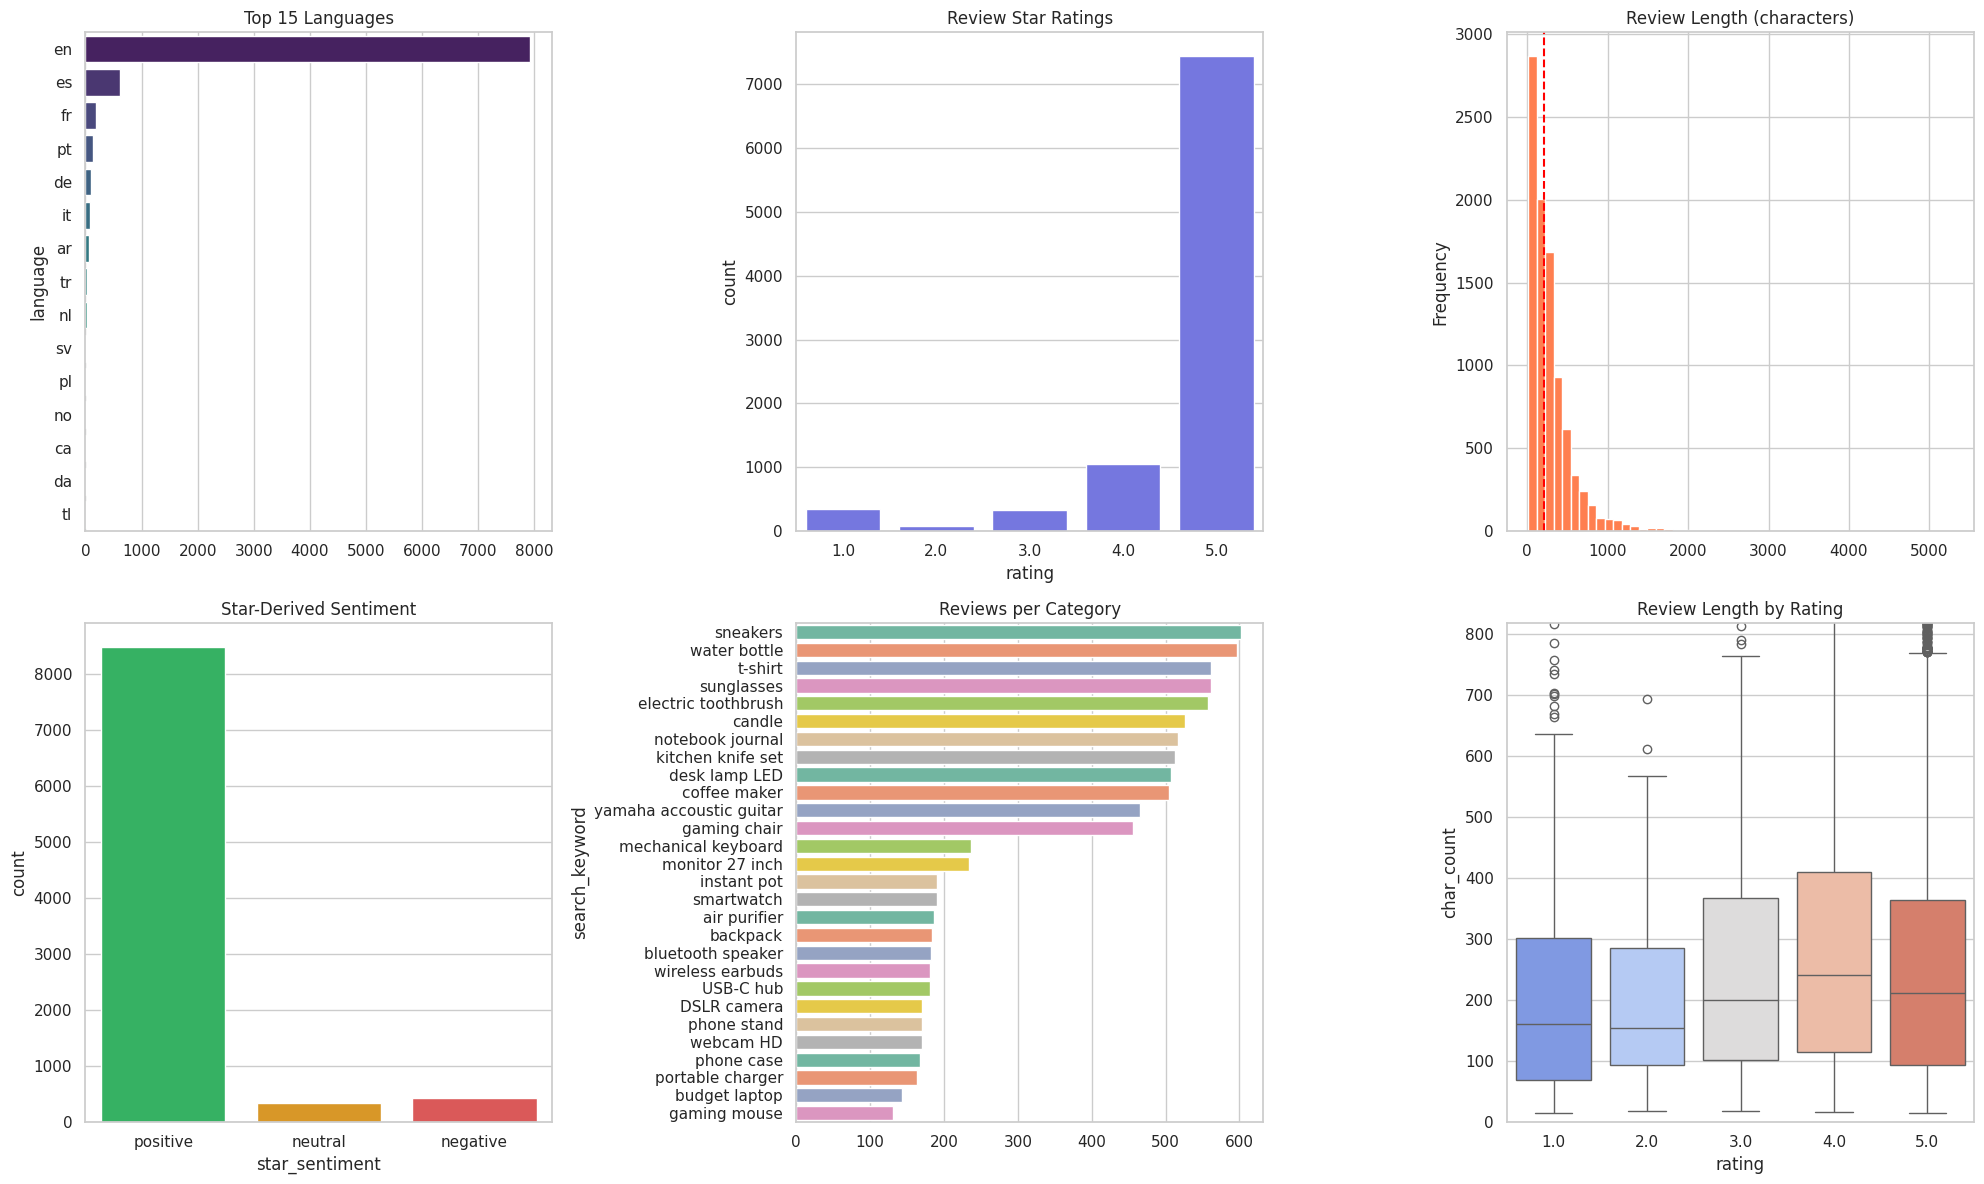

English share: 85.6%
Non-English reviews: 1328


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

lang_counts = reviews['language'].value_counts().head(15)
sns.barplot(x=lang_counts.values, y=lang_counts.index, ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Top 15 Languages')

sns.countplot(data=reviews, x='rating', ax=axes[0,1], color='#6366F1')
axes[0,1].set_title('Review Star Ratings')

reviews['char_count'] = reviews['body_clean'].fillna('').str.len()
reviews['char_count'].plot.hist(bins=50, ax=axes[0,2], color='coral', edgecolor='white')
axes[0,2].set_title('Review Length (characters)')
axes[0,2].axvline(reviews['char_count'].median(), color='red', linestyle='--')

sns.countplot(data=reviews, x='star_sentiment', order=['positive','neutral','negative'],
              ax=axes[1,0], palette={'positive':'#22C55E','neutral':'#F59E0B','negative':'#EF4444'})
axes[1,0].set_title('Star-Derived Sentiment')

rev_per_cat = reviews['search_keyword'].value_counts()
sns.barplot(x=rev_per_cat.values, y=rev_per_cat.index, ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Reviews per Category')

sns.boxplot(data=reviews, x='rating', y='char_count', ax=axes[1,2], palette='coolwarm')
axes[1,2].set_title('Review Length by Rating')
axes[1,2].set_ylim(0, reviews['char_count'].quantile(0.95))

plt.tight_layout()
plt.savefig(CLEAN_DIR / 'review_eda.png', dpi=160, bbox_inches='tight')
plt.show()

print(f'English share: {reviews["language"].eq("en").mean():.1%}')
print(f'Non-English reviews: {(~reviews["language"].eq("en")).sum()}')

## 8. Image and video coverage

In [11]:
print('=== Image Coverage ===')
if 'image_url' in products.columns:
    has_image = products['image_url'].notna().sum()
    print(f'  Has image_url: {has_image} / {len(products)} ({has_image/len(products):.1%})')

image_dir = PROJECT / 'data' / 'images'
if image_dir.exists():
    image_files = list(image_dir.glob('*.jpg')) + list(image_dir.glob('*.png'))
    print(f'  Downloaded images: {len(image_files)} files')
    asins_with_images = {f.stem for f in image_files}
    matched = asins_with_images & set(products['asin'])
    print(f'  ASIN match: {len(matched)} / {len(products)}')

print('\n=== Video Coverage ===')
if 'has_video' in products.columns:
    display(products['has_video'].value_counts().to_frame('count'))
if 'video_url' in products.columns:
    print(f'  Has video_url: {products["video_url"].notna().sum()}')

=== Image Coverage ===
  Has image_url: 859 / 859 (100.0%)
  Downloaded images: 859 files
  ASIN match: 859 / 859

=== Video Coverage ===


,count
has_video,
True,737
False,122


  Has video_url: 600


## 9. Data quality summary

In [12]:
print('=' * 55)
print('  FINAL DATA QUALITY SUMMARY')
print('=' * 55)

summary = {
    'Products': len(products),
    'Reviews': len(reviews),
    'Categories': products['search_keyword'].nunique(),
    'Languages detected': reviews['language'].nunique(),
    'English review share': f"{reviews['language'].eq('en').mean():.1%}",
    'Products with price': int(products['has_price'].sum()) if 'has_price' in products.columns else 'N/A',
    'Products with brand': int(products['brand'].notna().sum()),
    'Products with image': int(products['image_url'].notna().sum()) if 'image_url' in products.columns else 'N/A',
    'Reviews with body text': int(reviews['body_clean'].notna().sum()),
    'Reviews with star rating': int(reviews['rating'].notna().sum()),
    'Duplicate review IDs': int(reviews['review_id'].duplicated().sum()),
}

display(pd.Series(summary, name='value').to_frame())

print(f'\nParquet files saved to: {CLEAN_DIR}')
print(f'  products_clean.parquet: {len(products)} rows')
print(f'  reviews_clean.parquet:  {len(reviews)} rows')
print(f'\nAll four feature notebooks read from these files via load_clean().')

  FINAL DATA QUALITY SUMMARY


,value
Products,859
Reviews,9251
Categories,28
Languages detected,25
English review share,85.6%
Products with price,786
Products with brand,830
Products with image,859
Reviews with body text,9251
Reviews with star rating,9251



Parquet files saved to: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/clean
  products_clean.parquet: 859 rows
  reviews_clean.parquet:  9251 rows

All four feature notebooks read from these files via load_clean().


In [13]:
# === DROP TRACE ===
from analysis.cleaning import load_raw, clean_text, clean_review_text

products_raw, reviews_raw = load_raw()
print(f'1. Raw reviews from JSONL:        {len(reviews_raw)}')

# Simulate what clean_reviews does step by step
df = reviews_raw.copy()
df['body_clean'] = df.get('body', pd.Series(index=df.index, dtype='object')).map(clean_review_text)
df['title_clean'] = df.get('title', pd.Series(index=df.index, dtype='object')).map(clean_review_text)
df['word_count'] = df['body_clean'].fillna('').str.split().str.len()

empty = (df['word_count'] < 1).sum()
print(f'2. Empty/no text body:            -{empty}')
df = df[df['word_count'] >= 1].copy()

dedup_cols = [c for c in ('asin','reviewer_name','date','title_clean','body_clean') if c in df]
before = len(df)
df = df.drop_duplicates(dedup_cols, keep='first')
print(f'3. Exact duplicate reviews:       -{before - len(df)}')

# Then prepare_reviews adds its own dedup
from analysis.sentiment_checkpointed import prepare_reviews
final = prepare_reviews(reviews)
print(f'4. After prepare_reviews dedup:   {len(final)}')
print(f'\n   Total dropped: {len(reviews_raw) - len(final)}')
print(f'   Final count:   {len(final)}')

1. Raw reviews from JSONL:        9886
2. Empty/no text body:            -6
3. Exact duplicate reviews:       -0
4. After prepare_reviews dedup:   9251

   Total dropped: 635
   Final count:   9251


In [14]:
import hashlib
# Show what prepare_reviews drops
df_temp = reviews.copy()
df_temp['_id'] = df_temp.fillna('').astype(str)[
    ['asin','reviewer_name','date','body_clean']
].agg('|'.join, axis=1).map(lambda x: hashlib.sha1(x.encode()).hexdigest()[:20])

dupes = df_temp[df_temp.duplicated('_id', keep=False)].sort_values('_id')
print(f'Duplicate groups: {dupes["_id"].nunique()}')
display(dupes[['asin','reviewer_name','date','title_clean','body_clean']].head(10))

Duplicate groups: 0


,asin,reviewer_name,date,title_clean,body_clean


In [15]:
from analysis.sentiment_checkpointed import prepare_reviews
import hashlib

df = reviews.copy()
print(f'Start: {len(df)}')

# Step 1: empty body filter (same as prepare_reviews line 1)
mask = df.body_clean.notna() & df.body_clean.astype(str).str.strip().ne("")
print(f'After empty body filter: {mask.sum()} (dropped {(~mask).sum()})')
df = df[mask].copy()

# Step 2: check which identity columns actually exist
id_cols = [c for c in ["asin","reviewer_name","date","body_clean"] if c in df]
print(f'Identity columns found: {id_cols}')
missing_cols = [c for c in ["asin","reviewer_name","date","body_clean"] if c not in df]
if missing_cols:
    print(f'⚠️ MISSING columns: {missing_cols} — this reduces uniqueness!')

# Step 3: generate review_id same way as prepare_reviews
identity = df.fillna("").astype(str)[id_cols].agg("|".join, axis=1)
df["_test_id"] = identity.map(lambda x: hashlib.sha1(x.encode()).hexdigest()[:20])

total = len(df)
unique = df["_test_id"].nunique()
print(f'Total reviews: {total}')
print(f'Unique review_ids: {unique}')
print(f'Would be dropped by dedup: {total - unique}')

# Step 4: show what's colliding
if total > unique:
    dupes = df[df.duplicated("_test_id", keep=False)].sort_values("_test_id")
    print(f'\nDuplicate groups: {dupes["_test_id"].nunique()}')

    # Check NaN rates in identity columns
    print('\nNaN rates in identity columns:')
    for col in id_cols:
        na = df[col].isna().sum()
        print(f'  {col}: {na} ({na/len(df)*100:.1f}%)')

    # Show sample collisions
    print('\nSample colliding reviews:')
    sample_id = dupes["_test_id"].iloc[0]
    display(dupes[dupes["_test_id"] == sample_id][["asin","reviewer_name","date","body_clean","title_clean"]].head())

Start: 9251
After empty body filter: 9251 (dropped 0)
Identity columns found: ['asin', 'reviewer_name', 'date', 'body_clean']
Total reviews: 9251
Unique review_ids: 9251
Would be dropped by dedup: 0


In [16]:
from analysis.cleaning import load_raw, clean_review_text

_, reviews_raw = load_raw()
print(f'1. Raw from JSONL: {len(reviews_raw)}')

df = reviews_raw.copy()

# Step A: text cleaning (normalization)
df['body_clean'] = df.get('body').map(clean_review_text)
df['title_clean'] = df.get('title').map(clean_review_text)

# Step B: empty filter
mask = df['body_clean'].fillna('').str.split().str.len() >= 1
print(f'2. After empty body filter: {mask.sum()} (dropped {(~mask).sum()})')
df = df[mask].copy()

# Step C: 5-column dedup (what clean_reviews does)
dedup_cols = [c for c in ('asin','reviewer_name','date','title_clean','body_clean') if c in df]
before = len(df)
df = df.drop_duplicates(dedup_cols, keep='first')
print(f'3. After 5-col dedup (post-normalization): {len(df)} (dropped {before - len(df)})')

# Step D: review_id dedup
import hashlib
df['_rid'] = df.fillna('').astype(str)[
    [c for c in ('asin','reviewer_name','date','body_clean') if c in df]
].agg('|'.join, axis=1).map(lambda x: hashlib.sha1(x.encode()).hexdigest()[:20])
before = len(df)
df = df.drop_duplicates('_rid', keep='first')
print(f'4. After review_id dedup: {len(df)} (dropped {before - len(df)})')

print(f'\nTotal dropped: {len(reviews_raw) - len(df)}')
print(f'Final: {len(df)}')

1. Raw from JSONL: 9886
2. After empty body filter: 9880 (dropped 6)
3. After 5-col dedup (post-normalization): 9880 (dropped 0)
4. After review_id dedup: 9880 (dropped 0)

Total dropped: 6
Final: 9880


In [17]:
from analysis.cleaning import load_raw, clean_review_text
import hashlib

def _review_id(row):
    identity = "|".join(str(row.get(c) or "") for c in ("asin", "reviewer_name", "date", "body_clean"))
    return hashlib.sha1(identity.encode("utf-8")).hexdigest()[:20]

_, reviews_raw = load_raw()
df = reviews_raw.copy()

df['body_clean'] = df.get('body').map(clean_review_text)
df['title_clean'] = df.get('title').map(clean_review_text)
df['word_count'] = df['body_clean'].fillna('').str.split().str.len()
df = df[df['word_count'] >= 1].copy()

dedup_cols = [c for c in ('asin','reviewer_name','date','title_clean','body_clean') if c in df]
df = df.drop_duplicates(dedup_cols, keep='first').copy()
print(f'After 5-col dedup: {len(df)}')

print('\nNaN rates in identity columns:')
for col in ['asin', 'reviewer_name', 'date', 'title_clean', 'body_clean']:
    na = df[col].isna().sum()
    print(f'  {col}: {na} ({na/len(df)*100:.1f}%)')

df['review_id'] = df.apply(_review_id, axis=1)
before = len(df)
df_deduped = df.drop_duplicates('review_id', keep='first')
dropped = before - len(df_deduped)
print(f'\nAfter review_id dedup: {len(df_deduped)} (dropped {dropped})')

if dropped > 0:
    dupes = df[df.duplicated('review_id', keep=False)].sort_values('review_id')
    print(f'Colliding review_id groups: {dupes["review_id"].nunique()}')
    sample_id = dupes['review_id'].iloc[0]
    collision = dupes[dupes['review_id'] == sample_id]
    display(collision[['asin','reviewer_name','date','title_clean','body_clean']].head())

After 5-col dedup: 9880

NaN rates in identity columns:
  asin: 0 (0.0%)
  reviewer_name: 0 (0.0%)
  date: 0 (0.0%)
  title_clean: 0 (0.0%)
  body_clean: 0 (0.0%)

After review_id dedup: 9880 (dropped 0)
